# 05 · Holdout and registration

**Champion (chosen before this notebook, from cross-validation only):** LightGBM with default parameters, the trend + residual target, ERA5 (`obs`) training weather, Uri excluded, and 42 features.

1. **Holdout, scored once.**
   - Train on target days 2016-01-12 → 2025-08-01.
   - Score 2025-08-10 → 2026-10-09 on archived forecast weather, never seen by any earlier notebook.
   - The baseline (`same_hour_latest`) is scored on exactly the same hours.
2. **Production fit.** The same recipe retrained on everything through 2026-10-09, so the deployed model has the latest data.
3. **Registration** in the MLflow Model Registry as `shef2-day-ahead`. The packaged model includes the fitted trend line, the bundle, the feature list and the forecast-completeness gate.
4. **Round trip:** loading the registered model must reproduce the in-memory predictions exactly.

In [1]:
%matplotlib inline
import json, tempfile, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
from shef.config import REPORTS, ROOT
from shef.models import data, folds, plots, report, tracking
from shef.models.metrics import score
from shef.models.predict import Champion, ChampionPyfunc

mlflow = tracking.init()
selection = json.loads((REPORTS / "p3_selection.json").read_text())
features = selection["features"]
tables = data.load_tables(features)
{k: selection[k] for k in ("model", "target", "train_source", "uri", "params", "weather_model")}

C:\Users\hp\Documents\ML_AI_Projects\SHEF2.0\.venv\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


{'model': 'lgbm',
 'target': 'trend',
 'train_source': 'obs',
 'uri': 'exclude',
 'params': {},
 'weather_model': 'gfs_seamless'}

## 1 · Holdout

In [2]:
fd = data.holdout_data(tables, train_source="obs", uri="exclude", final=True)
proxy = tables["proxy"]
in_window = proxy[folds.holdout_mask(proxy, final=True) & ~proxy["is_uri"]]
print(f"train rows {len(fd.train):,} (to {folds.target_day(fd.train).max()}); "
      f"holdout rows scored {len(fd.val):,} of {len(in_window):,} "
      f"({in_window['temp_c'].isna().sum()} without an archived forecast)")

champ = Champion.fit(fd.train, features, target_kind="trend", params=selection["params"])
hold = fd.val[["ts_utc", "issue_time_utc", "lead_hours", "hour", "month", "y", "load_same_hour_latest"]].copy()
hold["pred"] = champ.predict(fd.val)
hold["baseline"] = hold["load_same_hour_latest"]
hold["fold"] = "holdout"
res = pd.DataFrame({"champion": score(hold["y"], hold["pred"]), "baseline same_hour_latest": score(hold["y"], hold["baseline"])}).T.round(2)
res

train rows 83,494 (to 2025-08-01); holdout rows scored 10,224 of 10,224 (0 without an archived forecast)


,mape,peak_mape,rmse,bias_pct
champion,3.79,3.38,482.24,-0.17
baseline same_hour_latest,7.62,3.79,1013.23,0.08


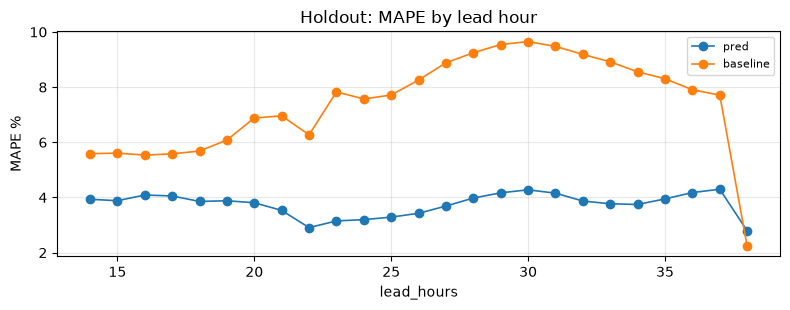

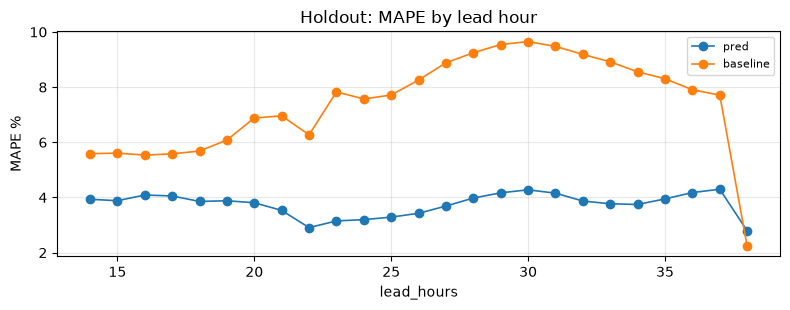

In [3]:
plots.compare_by(hold, "lead_hours", ["pred", "baseline"], "Holdout: MAPE by lead hour")

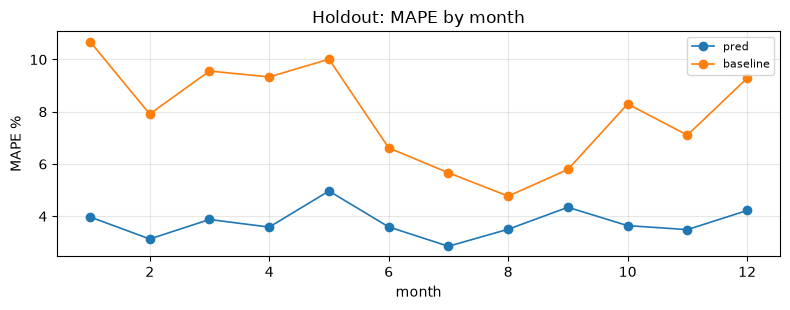

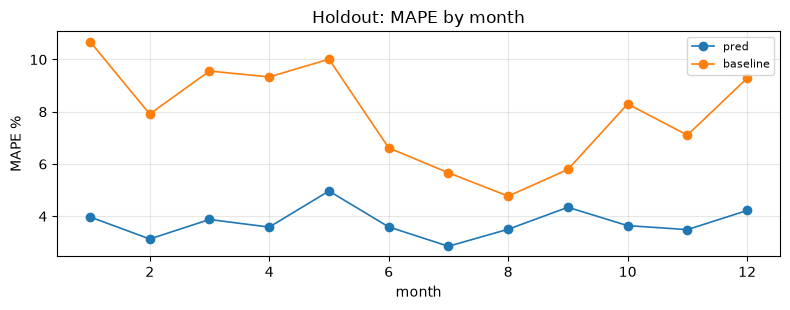

In [4]:
plots.compare_by(hold, "month", ["pred", "baseline"], "Holdout: MAPE by month")

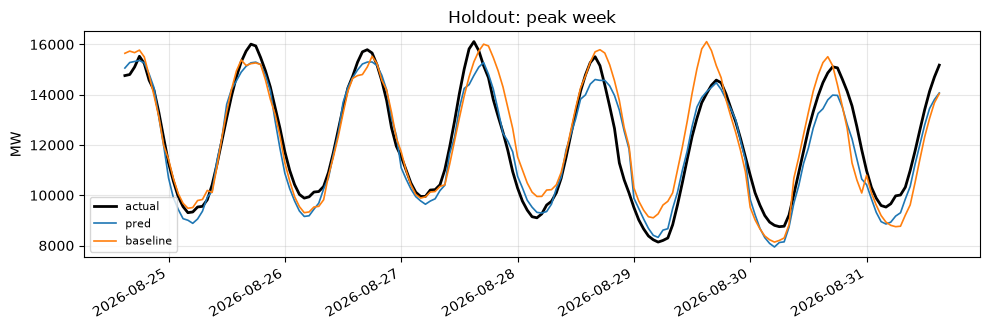

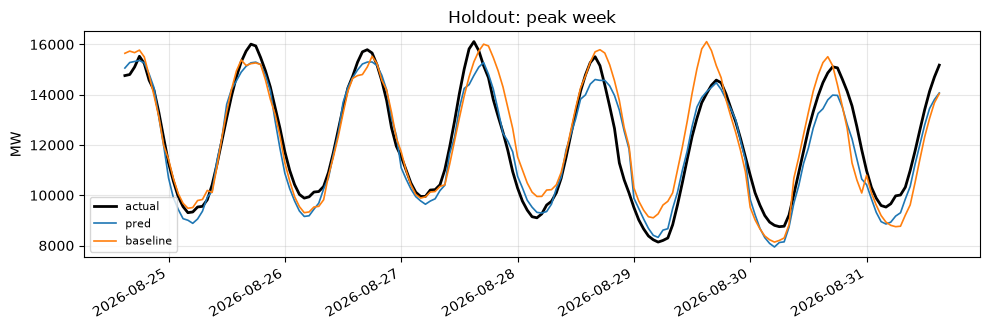

In [5]:
plots.peak_week(hold, ["pred", "baseline"], "Holdout: peak week")

In [6]:
cv_vs_holdout = pd.DataFrame({
    "cv (3 folds, with forecast)": {"mape": selection["cv_mape_with_forecast"], "peak_mape": selection["cv_peak_mape_with_forecast"]},
    "holdout": {"mape": res.loc["champion", "mape"], "peak_mape": res.loc["champion", "peak_mape"]},
}).T
cv_vs_holdout

,mape,peak_mape
"cv (3 folds, with forecast)",4.18,2.99
holdout,3.79,3.38


In [7]:
with tempfile.TemporaryDirectory() as tmp:
    path = champ.save(Path(tmp) / "champion_holdout")
    hold_metrics = {f"holdout_{k}": v for k, v in res.loc["champion"].items()}
    hold_metrics.update({f"holdout_baseline_{k}": v for k, v in res.loc["baseline same_hour_latest"].items()})
    report.log_scored("P3_holdout_lgbm_trend", hold.assign(fold=1), "pred",
                      {"model": "lgbm", "target": "trend", "train_source": "obs", "uri": "exclude", "features": features,
                       "train_end": str(folds.target_day(fd.train).max()), "holdout": f"{folds.HOLDOUT[0]}..{folds.HOLDOUT[1]}"},
                      dicts={"holdout_scores": res.reset_index().to_dict("list")},
                      files={"champion": path}, tags={"experiment": "holdout"})
print(hold_metrics)

🏃 View run P3_holdout_lgbm_trend at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/1e835eb4477c465583e865f7b60e9246
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


{'holdout_mape': 3.79, 'holdout_peak_mape': 3.38, 'holdout_rmse': 482.24, 'holdout_bias_pct': -0.17, 'holdout_baseline_mape': 7.62, 'holdout_baseline_peak_mape': 3.79, 'holdout_baseline_rmse': 1013.23, 'holdout_baseline_bias_pct': 0.08}


## 2 · Production fit: same recipe, all data

In [8]:
obs = tables["obs"]
last = folds.HOLDOUT[1]
prod_rows = obs[(folds.target_day(obs) >= folds.TRAIN_START) & (folds.target_day(obs) <= last) & ~obs["is_uri"]].dropna(subset=["y"])
prod = Champion.fit(prod_rows, features, target_kind="trend", params=selection["params"])
print(f"production model trained on {len(prod_rows):,} rows, {folds.target_day(prod_rows).min()} → {folds.target_day(prod_rows).max()}")
print("trend line: intercept %.1f MW, slope %.1f MW/yr" % (prod.target.intercept, prod.target.slope))

production model trained on 93,910 rows, 2016-01-12 → 2026-10-09
trend line: intercept 5984.0 MW, slope 317.6 MW/yr


## 3 · Register

In [9]:
tmp = tempfile.mkdtemp()
art = prod.save(Path(tmp) / "champion")
with mlflow.start_run(run_name="P3_production_lgbm_trend") as run:
    mlflow.set_tags({**tracking.provenance(), "experiment": "production", "weather_model_for_serving": selection["weather_model"]})
    mlflow.log_params({"model": "lgbm", "target": "trend", "train_source": "obs", "uri": "exclude",
                       "train_rows": len(prod_rows), "train_end": str(last), "n_features": len(features)})
    mlflow.log_metrics({**hold_metrics, "cv_mape_with_forecast": selection["cv_mape_with_forecast"],
                        "cv_peak_mape_with_forecast": selection["cv_peak_mape_with_forecast"]})
    mlflow.log_dict(selection, "p3_selection.json")
    info = mlflow.pyfunc.log_model(name="model", python_model=ChampionPyfunc(), artifacts={"champion": str(art)},
                                   code_paths=[str(ROOT / "src" / "shef")], registered_model_name="shef2-day-ahead")
print("registered:", info.registered_model_version, "| run", run.info.run_id)

2026/10/12 18:15:57 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


2026/10/12 18:16:25 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Successfully registered model 'shef2-day-ahead'.


2026/10/12 18:18:27 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: shef2-day-ahead, version 1


Created version '1' of model 'shef2-day-ahead'.


🏃 View run P3_production_lgbm_trend at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3/runs/7b8094a877234751a0cfe5536de1cb45
🧪 View experiment at: https://dagshub.com/dunnioluajayi/electricity-distribution-forecast.mlflow/#/experiments/3


registered: 1 | run 7b8094a877234751a0cfe5536de1cb45


## 4 · Round trip

In [10]:
loaded = mlflow.pyfunc.load_model(f"models:/shef2-day-ahead/{info.registered_model_version}")
day = fd.val[folds.target_day(fd.val) == folds.target_day(fd.val).max()]
a, b = prod.predict(day), np.asarray(loaded.predict(day))
print(f"{len(day)} rows, max abs difference {np.max(np.abs(a - b)):.2e} MW")
assert np.allclose(a, b, rtol=1e-9)

24 rows, max abs difference 0.00e+00 MW


## Reading

- **On the holdout the champion halves the baseline's error: 3.79% vs 7.62% MAPE, and 482 vs 1,013 MW RMSE, with almost no bias (−0.17%).**
  - This is the honest number: forecast weather, only data available at 10:00 Central, 14–37 h ahead, on 14 months no earlier notebook touched.
  - All 10,224 holdout hours have an archived forecast, so none were excluded.
- **The holdout came in better than CV (4.18%).** It has more training history and no archive gap, so nothing here suggests overfitting to the folds.
- **Peaks are the closer contest: 3.38% vs the baseline's 3.79%.** That gap is smaller than in CV (2.99% vs 5.70%). The holdout's peak hours fell mostly in the steady late-summer 2025 heat, where yesterday's same-hour load is already a strong guess. Peak behaviour is worth watching in live monitoring (P6).
- **Production model:** the same recipe retrained on 93,910 rows (2016-01-12 → 2026-10-09). Its trend line is +318 MW per year of load growth. It's registered as `shef2-day-ahead` v1, with holdout metrics, CV metrics and git/DVC provenance.
- **The registered model reproduces in-memory predictions exactly**, and it carries the forecast gate: it refuses to predict if any target hour lacks forecast temperature. Serving must request `models=gfs_seamless`.